
Vanilla feature correlations:
                   feature_1                                feature_2  correlation
  battle_entities__fly_speed     battle_entities__flying_charge_speed     0.998180
  battle_entities__run_speed            battle_entities__charge_speed     0.906091
land_units__bonus_hit_points                 melee_weapons__ap_damage     0.901240
         main_units__num_men               main_units__is_high_threat    -0.880215
land_units__bonus_hit_points melee_weapons__splash_attack_max_attacks     0.858509
    melee_weapons__ap_damage melee_weapons__splash_attack_max_attacks     0.852050
main_units__recruitment_cost                  main_units__upkeep_cost     0.838752
     battle_entities__radius                    battle_entities__mass     0.827058
         main_units__num_men                    melee_weapons__damage    -0.813510
  main_units__is_high_threat             land_units__bonus_hit_points     0.810390
         main_units__num_men                   projectil

c:\Users\jdhey\anaconda3\envs\systools\Lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


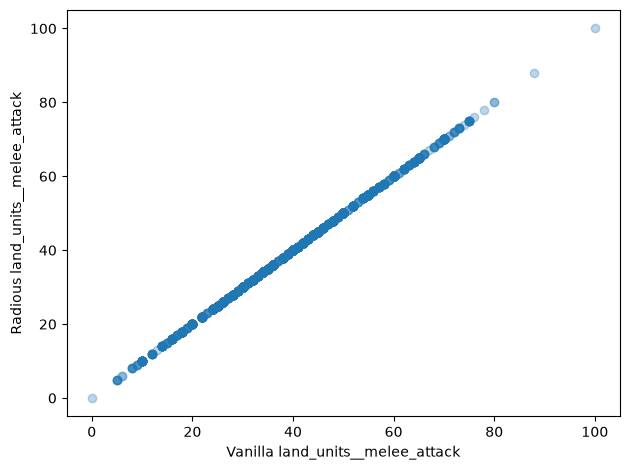

In [3]:
import json
import pandas as pd
import matplotlib.pyplot as plt

with open("./cleaned_data/pairs.json", encoding="utf-8") as file:
    pairs = json.load(file)

vanilla = pd.DataFrame([pair["vanilla"] for pair in pairs])
radious = pd.DataFrame([pair["radious"] for pair in pairs])

# Keep numeric stats; exclude the exported row index.
X = vanilla.select_dtypes(include="number").drop(columns="Index", errors="ignore")
radious_stats = radious.reindex(columns=X.columns)
changes = radious_stats - X

# print("Missing values:")
# print(X.isna().sum())

print("\nVanilla feature correlations:")
corr = X.corr(method="spearman")
strong = []

for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        correlation = corr.iloc[i, j]

        if abs(correlation) >= 0.8:
            feature_1 = corr.columns[i]
            feature_2 = corr.columns[j]
            strong.append([feature_1, feature_2, correlation])

strong = pd.DataFrame(
    strong,
    columns=["feature_1", "feature_2", "correlation"]
)

strong = strong.sort_values(
    "correlation",
    key=abs,
    ascending=False
)

print(strong.to_string(index=False))

print("\nPercentage changed among available pairs:")
available = X.notna() & radious_stats.notna()
changed = X.ne(radious_stats) & available
print(changed.sum().div(available.sum()).mul(100))

# Choose the stat to inspect.
stat = "land_units__melee_attack"

print(f"\nVanilla features correlated with the change in {stat}:")
print(
    X.corrwith(changes[stat], method="spearman")
    .sort_values(key=lambda values: values.abs(), ascending=False)
)

plt.scatter(X[stat], radious_stats[stat], alpha=0.3)
plt.xlabel(f"Vanilla {stat}")
plt.ylabel(f"Radious {stat}")
plt.tight_layout()
plt.show()

In [ ]:
import json
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

import joblib



reference_columns = [
    "unit",
    "main_units__land_unit",
    "land_units__man_entity",
    "land_units__primary_melee_weapon",
    "land_units__primary_missile_weapon",
    "land_units__mount",
    "land_units__engine",
    "land_units__armour",
    "land_units__shield",
    "missile_weapons__default_projectile",
]

def load_data():
    with open("./cleaned_data/pairs.json", encoding="utf-8") as file:
        pairs = json.load(file)
    vanilla_rows = []
    radious_rows = []

    for pair in pairs:
        vanilla_rows.append(pair["vanilla"])
        radious_rows.append(pair["radious"])

    vanilla = pd.DataFrame(vanilla_rows)
    radious = pd.DataFrame(radious_rows)

    unit_keys = vanilla["unit"].copy()
    return unit_keys, vanilla, radious

# columns not needed for training
reference_columns = [
    "unit",
    "radious_part",
    "main_units__land_unit",
    "land_units__man_entity",
    "land_units__primary_melee_weapon",
    "land_units__primary_missile_weapon",
    "land_units__mount",
    "land_units__engine",
    "land_units__articulated_record",
    "land_units__mounted_draughts",
    "missile_weapons__default_projectile",
]

def prepare_data():
    unit_keys, vanilla, radious = load_data()
    
    X = vanilla.copy()
    
    for column in vanilla.columns:
        if column.endswith("__key") or column in reference_columns:
            X = X.drop(columns=column)
            
    y = pd.DataFrame(index=radious.index)
    
    categorical_names = [
        "main_units__caste",
        "main_units__weight",
        "land_units__category",
        "land_units__class",
        "land_units__armour",
        "land_units__shield",
        "battle_entities__type",
        "battle_entities__size",
        "melee_weapons__melee_weapon_type",
        "melee_weapons__splash_attack_target_size",
    ]

    # all columns not in categorical are treated as numerical
    numeric_columns = []
    for column in X.columns:
        if column not in categorical_names:
            numeric_columns.append(column)
    
    minimum_changed_units = 10

    for column in numeric_columns:
        before = vanilla[column]
        after = radious[column]

        available = before.notna() & after.notna()
        changed = available & before.ne(after)

        changed_count = changed.sum()

        # only add a label if there are enough units that have had this column changed
        if changed_count >= minimum_changed_units:
            y["delta_" + column] = after - before
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=42)
    
    numeric_pipeline = Pipeline([
        ("impute", SimpleImputer(
            strategy="median",
            add_indicator=True,
            keep_empty_features=True,
        )),
    ])
    categorical_pipeline = Pipeline([
        ("impute", SimpleImputer(
            strategy="constant",
            fill_value="unknown",
            keep_empty_features=True,
        )),
        ("encode", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False,
        )),
    ])
    
    preprocessor = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_columns),
        ("categorical", categorical_pipeline, categorical_names),
    ])
    
    X_train_processed = preprocessor.fit_transform(X_train)
    X_test_processed = preprocessor.transform(X_test)
    
    feature_names = preprocessor.get_feature_names_out()
    
    X_train_processed = pd.DataFrame(
        X_train_processed,
        columns=feature_names,
        index=X_train.index,
    )

    X_test_processed = pd.DataFrame(
        X_test_processed,
        columns=feature_names,
        index=X_test.index,
    )

    print("Training inputs:", X_train_processed.shape)
    print("Test inputs:", X_test_processed.shape)
    print("Training targets:", y_train.shape)
    print("Test targets:", y_test.shape)
    
    X_train_processed.to_json("./train_data/X_train.json", orient="records", indent=2)
    X_test_processed.to_json("./train_data/X_test.json", orient="records", indent=2)
    y_train.to_json("./train_data/y_train.json", orient="records", indent=2)
    y_test.to_json("./train_data/y_test.json", orient="records", indent=2)
    
    joblib.dump(preprocessor, "./model/preprocessor.joblib")
    
    
    
    

In [44]:
if __name__ == "__main__":
    prepare_data()

Training inputs: (2241, 227)
Test inputs: (561, 227)
Training targets: (2241, 37)
Test targets: (561, 37)
